# un MLP à une couche cachée


## 1. Imports et configuration

In [ ]:
import os, time, random, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.colors import LinearSegmentedColormap
from IPython.display import display

import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader

from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix, classification_report
#charte graphique
from charte_graphique import appliquer_charte, BLEU, ROUGE, BLANC, GRIS, teintes
appliquer_charte()
warnings.filterwarnings("ignore")

#pour les cartes de chaleur à val positives
cmap_bleu = LinearSegmentedColormap.from_list("charte_bleu", [BLANC, BLEU])


def set_seed(seed=0):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)

set_seed(0)
torch.set_num_threads(1)     
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device :", device, "| torch", torch.__version__)

Device : cpu | torch 2.15.0+cpu


## load processed data

In [8]:
DATA_DIR = os.environ.get("HAR_DIR", "../data/processed_har_data")

train_df = pd.read_csv(f"{DATA_DIR}/train_processed.csv")
val_df   = pd.read_csv(f"{DATA_DIR}/val_processed.csv")

feature_cols = [c for c in train_df.columns if c not in ("subject", "Activity")]
classes = sorted(train_df["Activity"].unique())            
class_to_idx = {c: i for i, c in enumerate(classes)}
n_classes = len(classes)

X_train_s = train_df[feature_cols].to_numpy(dtype=np.float32)
y_train   = train_df["Activity"].map(class_to_idx).to_numpy(dtype=np.int64)
X_val_s   = val_df[feature_cols].to_numpy(dtype=np.float32)
y_val     = val_df["Activity"].map(class_to_idx).to_numpy(dtype=np.int64)

print("classes :", class_to_idx)
print("X_train_s :", X_train_s.shape, X_train_s.dtype, "| y_train :", y_train.shape, y_train.dtype)
print("X_val_s   :", X_val_s.shape, "| y_val :", y_val.shape)
print("volontaires train :", train_df["subject"].nunique(), "| volontaires validation :", val_df["subject"].nunique())


classes : {'LAYING': 0, 'SITTING': 1, 'STANDING': 2, 'WALKING': 3, 'WALKING_DOWNSTAIRS': 4, 'WALKING_UPSTAIRS': 5}
X_train_s : (5657, 561) float32 | y_train : (5657,) int64
X_val_s   : (1695, 561) | y_val : (1695,)
volontaires train : 16 | volontaires validation : 5


In [9]:
#mini batchs pour l'entraînement et la validation
def make_loader(X, y, batch_size=128, shuffle=False, seed=0):
    g = torch.Generator(); g.manual_seed(seed) #décider l'ordre dans lesquels les exps sont mélangés avec la meme graine on obtient à chaque fois le même ordre à chaque exécution -> reproductibilité
    #former les paires (entrée X , étiquettes y)
    ds = TensorDataset(torch.from_numpy(X), torch.from_numpy(y))
    return DataLoader(ds, batch_size=batch_size, shuffle=shuffle, generator=g if shuffle else None)

train_loader      = make_loader(X_train_s, y_train, 128, shuffle=True, seed=0)
train_eval_loader = make_loader(X_train_s, y_train, 512)     #mesurer la perte sur tout le train sans mettre a jour les poids, sans mélange , L’ordre n’a aucune importance pour mesurer
val_loader        = make_loader(X_val_s,   y_val,   512)

##  MLP à 1 couche cachée


In [10]:
EPOCHS   = 150   
PATIENCE = 10   
ACTIVATIONS = {"relu": nn.ReLU, "tanh": nn.Tanh, "sigmoid": nn.Sigmoid}

class MLP_ONE_HIDDEN_LAYER(nn.Module):
    
    def __init__(self, in_dim, hidden=64, n_classes=6, act="relu"):
        super().__init__()
        self.hidden_layer = nn.Linear(in_dim, hidden)
        self.act = ACTIVATIONS[act]()
        self.out_layer = nn.Linear(hidden, n_classes)

    def forward(self, x):
        return self.out_layer(self.act(self.hidden_layer(x)))
#compter le nombre de paramètres du modèle qu'on peut ajuster
def count_params(model):
    return sum(p.numel() for p in model.parameters() if p.requires_grad)

in_dim = X_train_s.shape[1]
model = MLP_ONE_HIDDEN_LAYER(in_dim, hidden=64, n_classes=n_classes, act="relu")
print(model)
print("Nombre de paramètres :", count_params(model), "= (561*64 + 64) + (64*6 + 6)")

MLP_ONE_HIDDEN_LAYER(
  (hidden_layer): Linear(in_features=561, out_features=64, bias=True)
  (act): ReLU()
  (out_layer): Linear(in_features=64, out_features=6, bias=True)
)
Nombre de paramètres : 36358 = (561*64 + 64) + (64*6 + 6)


##  Vérifications avant d'entraîner

In [11]:
#fonction de perte
criterion = nn.CrossEntropyLoss()
print("perte attendue pour un réseau qui ne sait rien : ln(6) =", round(float(np.log(n_classes)), 3))

perte attendue pour un réseau qui ne sait rien : ln(6) = 1.792


In [12]:
# Perte initiale -> loss attendue ≈ ln(6) ≈ 1.792
set_seed(0)
m0 = MLP_ONE_HIDDEN_LAYER(in_dim, 64, n_classes, "relu").to(device)
m0.eval()
with torch.no_grad():
    logits = m0(torch.from_numpy(X_train_s).to(device))
    perte_initiale = criterion(logits, torch.from_numpy(y_train).to(device)).item()

perte_theorique = float(np.log(n_classes))
print(f"Perte initiale = {perte_initiale:.3f}  (attendu ≈ ln(6) = {perte_theorique:.3f})")
print(f"Écart absolu = {abs(perte_initiale - perte_theorique):.3f}")

Perte initiale = 1.841  (attendu ≈ ln(6) = 1.792)
Écart absolu = 0.049


écart à seulement 0,003 de la perte attendue -> bonne signe 
cette écart provient de l'intialisation aléatoire de début des poids 

Petit lot : loss 1.785 -> 0.00174 | accuracy sur le lot = 1.00


findfont: Failed to find font weight semibold for Arial, now using 700.


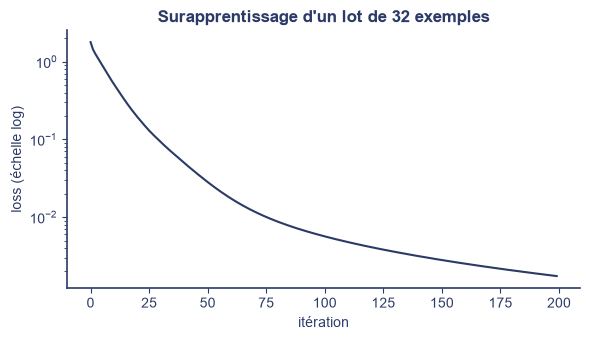

In [13]:
# OVERFITTING Le réseau doit pouvoir surapprendre un tout petit lot (32 exemples)
set_seed(0)
m1 = MLP_ONE_HIDDEN_LAYER(in_dim, 64, n_classes, "relu").to(device)
opt1 = torch.optim.Adam(m1.parameters(), lr=1e-3)
crit = nn.CrossEntropyLoss()
xb, yb = next(iter(make_loader(X_train_s, y_train, 32, shuffle=True, seed=0)))
xb, yb = xb.to(device), yb.to(device)

losses = []
for step in range(200):
    opt1.zero_grad()
    loss = crit(m1(xb), yb)
    loss.backward() #gradient 
    opt1.step()
    losses.append(loss.item())

acc_lot = (m1(xb).argmax(1) == yb).float().mean().item()
print(f"Petit lot : loss {losses[0]:.3f} -> {losses[-1]:.5f} | accuracy sur le lot = {acc_lot:.2f}")

fig, ax = plt.subplots(figsize=(6, 3.5))
ax.semilogy(losses, color=BLEU)
ax.set_title("Surapprentissage d'un lot de 32 exemples")
ax.set_xlabel("itération"); ax.set_ylabel("loss (échelle log)")
plt.tight_layout(); plt.show()

le réseau a mémorisé bien le petit lot donc le code de train fonctionne bien. 
perte au départ = 1,935 -> perte après 200 iterations = 0,00183 
accuracy = 100 %

##  Fonctions d'entraînement et d'évaluation

In [14]:
#choix de l'optimiseur
def make_optimizer(name, params, lr):
    if name == "sgd":  return torch.optim.SGD(params, lr=lr)
    if name == "sgdm": return torch.optim.SGD(params, lr=lr, momentum=0.9)
    if name == "adam": return torch.optim.Adam(params, lr=lr)
    raise ValueError(name)

In [15]:
#entrainement
def train_epoch(model, loader, criterion, optimizer):
    model.train()
    total, ys, ps = 0.0, [], []
    for xb, yb in loader:
        xb, yb = xb.to(device), yb.to(device)
        optimizer.zero_grad()
        out = model(xb)
        loss = criterion(out, yb)
        loss.backward()
        optimizer.step()
        total += loss.item() * len(yb)
        ps.append(out.argmax(1).cpu()); ys.append(yb.cpu())
    y, p = torch.cat(ys).numpy(), torch.cat(ps).numpy()
    return {"loss": total / len(y), "acc": accuracy_score(y, p), "f1": f1_score(y, p, average="macro")}

In [16]:
#evaluate en mesurant les performance sans modifier les poids 
import copy

@torch.no_grad()
def evaluate(model, loader):
    criterion = nn.CrossEntropyLoss()
    model.eval()
    total, ys, ps = 0.0, [], []
    for xb, yb in loader:
        xb, yb = xb.to(device), yb.to(device)
        out = model(xb)
        total += criterion(out, yb).item() * len(yb)
        ps.append(out.argmax(1).cpu()); ys.append(yb.cpu())
    y, p = torch.cat(ys).numpy(), torch.cat(ps).numpy()
    return {"loss": total / len(y), "acc": accuracy_score(y, p),
            "f1": f1_score(y, p, average="macro"), "pred": p}

def fit(model, optimizer, epochs, patience=None):
    criterion = nn.CrossEntropyLoss()
    hist = []
    best_loss, best_state, best_ep, attente = float("inf"), None, 0, 0
    for ep in range(1, epochs + 1):
        tr = train_epoch(model, train_loader, criterion, optimizer)
        va = evaluate(model, val_loader)
        hist.append({"epoch": ep,
                     "train_loss": tr["loss"], "train_acc": tr["acc"], "train_f1": tr["f1"],
                     "val_loss": va["loss"],   "val_acc": va["acc"],   "val_f1": va["f1"]})
        if va["loss"] < best_loss:                                   # nouvelle meilleure époque
            best_loss, best_ep, attente = va["loss"], ep, 0
            if patience: best_state = copy.deepcopy(model.state_dict())
        else:
            attente += 1
        if patience and attente >= patience:                         # plus d'amélioration : on arrête
            break
    if patience and best_state is not None:
        model.load_state_dict(best_state)                            # on restaure les meilleurs poids
    return pd.DataFrame(hist), best_ep

In [17]:
def run(act, opt, lr, epochs, hidden=64, seed=0, patience=None):
    set_seed(seed)
    model = MLP_ONE_HIDDEN_LAYER(in_dim, hidden, n_classes, act).to(device)
    optimizer = make_optimizer(opt, model.parameters(), lr)
    t0 = time.time()
    hist, best_ep = fit(model, optimizer, epochs, patience)
    return {"model": model, "hist": hist, "best_epoch": best_ep, "time": time.time() - t0}

## Réglage du pas d'apprentissage

LR range test : on fait croître le pas d'apprentissage de façon exponentielle pendant quelques itérations et on regarde la loss.

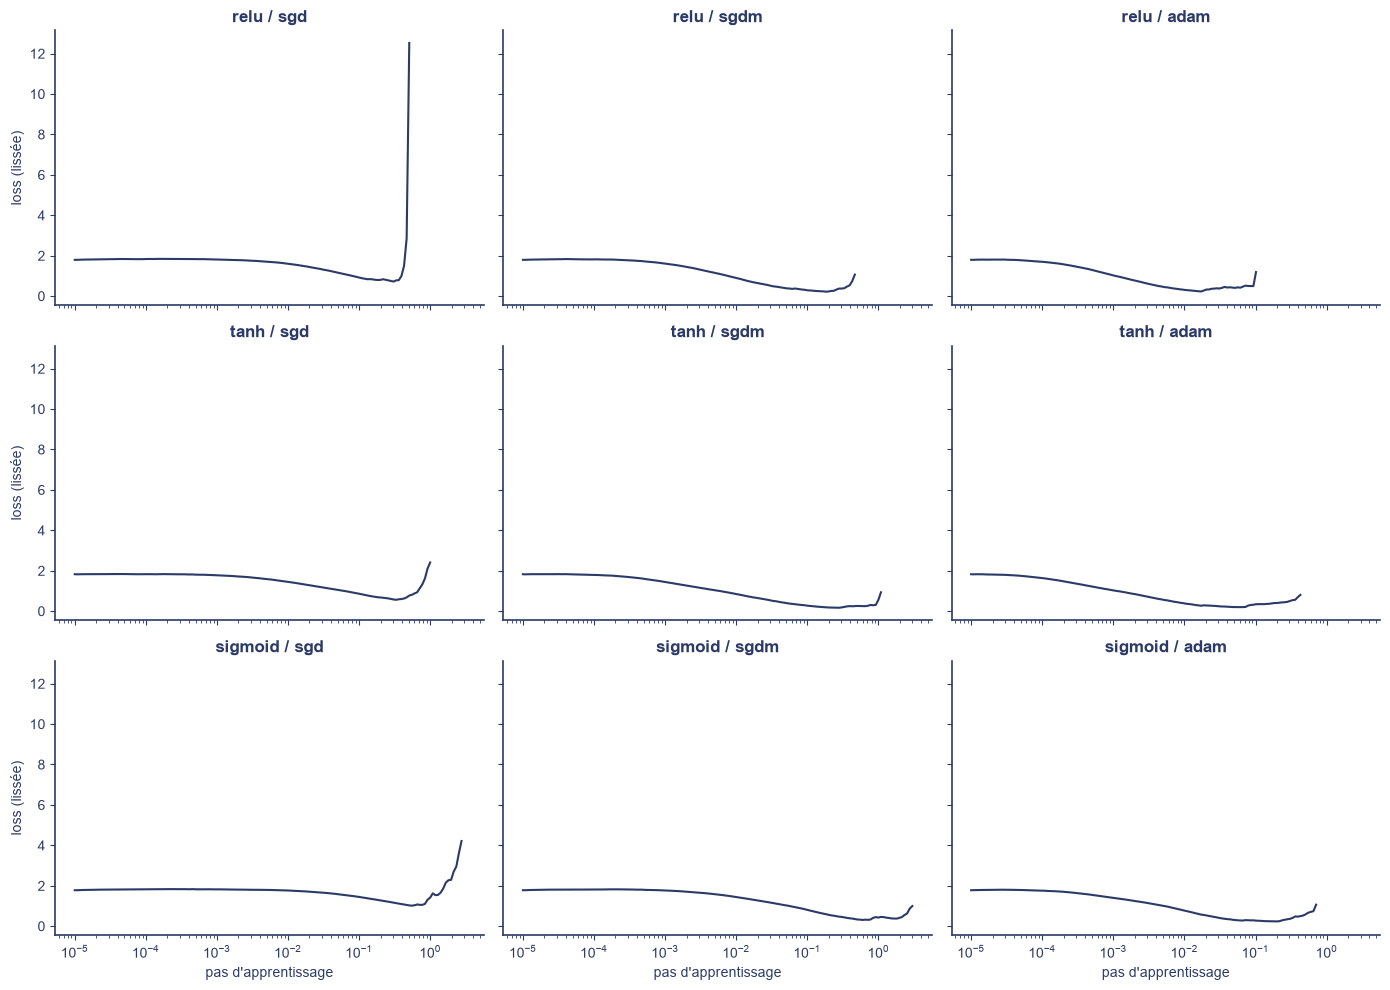

In [18]:
def lr_range_test(opt_name, act="relu", lr_min=1e-5, lr_max=3.0, n_iter=150):
    set_seed(0)
    model = MLP_ONE_HIDDEN_LAYER(in_dim, 64, n_classes, act).to(device)
    optimizer = make_optimizer(opt_name, model.parameters(), lr_min)
    crit = nn.CrossEntropyLoss()
    lrs = np.geomspace(lr_min, lr_max, n_iter)
    loader = make_loader(X_train_s, y_train, 128, shuffle=True, seed=0)
    it = iter(loader)
    smooth, out = None, []
    for i, lr in enumerate(lrs):
        for g in optimizer.param_groups:
            g["lr"] = lr
        try:
            xb, yb = next(it)
        except StopIteration:
            it = iter(loader); xb, yb = next(it)
        xb, yb = xb.to(device), yb.to(device)
        model.train()
        optimizer.zero_grad()
        loss = crit(model(xb), yb)
        loss.backward()
        optimizer.step()
        l = loss.item()
        smooth = l if smooth is None else 0.9 * smooth + 0.1 * l     # lissage de la courbe
        out.append(smooth)
        if i > 10 and (smooth > 4 * min(out) or not np.isfinite(smooth)):
            break                                                    # divergence : on arrête
    return lrs[:len(out)], np.array(out)

OPTS = ["sgd", "sgdm", "adam"]
fig, axes = plt.subplots(3, 3, figsize=(14, 10), sharex=True, sharey=True)
for i, act in enumerate(["relu", "tanh", "sigmoid"]):
    for j, o in enumerate(OPTS):
        lrs, ls = lr_range_test(o, act=act)
        axes[i, j].semilogx(lrs, ls, color=BLEU)
        axes[i, j].set_title(f"{act} / {o}")
for ax in axes[2]:
    ax.set_xlabel("pas d'apprentissage")
for ax in axes[:, 0]:
    ax.set_ylabel("loss (lissée)")
plt.tight_layout(); plt.show()

Le LR range test, réalisé pour chacun des 9 couples (activation, optimiseur), montre que le pas utile dépend de l’activation et de l’optimiseur : Adam fonctionne entre 10⁻³ et 10⁻¹ pour les trois activations, tandis que SGD demande des pas de l’ordre de 0,1 à 0,3 pour ReLU et tanh et nettement plus grands pour sigmoid, dont les gradients sont plus faibles

Le range test donne un ordre de grandeur, pas une valeur exacte. On affine donc avec une **petite grille logarithmique**, évaluée sur la validation (F1 macro), **pour chaque couple (activation, optimiseur)** : le bon pas dépend des deux.

In [20]:
LR_GRID = [1e-4, 3e-4, 1e-3, 3e-3, 1e-2, 3e-2, 1e-1, 3e-1, 1.0]
ACT_LIST = ["relu", "tanh", "sigmoid"]

GRID_EPOCHS   = 60   
GRID_PATIENCE = 5
GRID_FILE = "../results/etape4_grille_lr.csv"
os.makedirs("../results", exist_ok=True)

if os.path.exists(GRID_FILE):                   
    grid = pd.read_csv(GRID_FILE)
    print("grille rechargée depuis", GRID_FILE)
else:
    grid_rows = []
    for act in ACT_LIST:
        for o in OPTS:
            for lr in LR_GRID:
                r = run(act, o, lr, GRID_EPOCHS, patience=GRID_PATIENCE)
                best = r["hist"].iloc[r["best_epoch"] - 1]
                grid_rows.append({"act": act, "opt": o, "lr": lr,
                                  "val_f1": best["val_f1"], "val_loss": best["val_loss"]})
            print(f"{act} / {o} terminé")
    grid = pd.DataFrame(grid_rows)
    grid.to_csv(GRID_FILE, index=False)

# Meilleur pas pour chaque couple (activation, optimiseur)
best_lr = grid.loc[grid.groupby(["act", "opt"])["val_f1"].idxmax()].set_index(["act", "opt"])["lr"]
print("Pas d'apprentissage retenus :")
display(best_lr.to_frame("lr"))

relu / sgd terminé
relu / sgdm terminé
relu / adam terminé
tanh / sgd terminé
tanh / sgdm terminé
tanh / adam terminé
sigmoid / sgd terminé
sigmoid / sgdm terminé
sigmoid / adam terminé
Pas d'apprentissage retenus :


lr
act     opt        
relu    adam  0.030
        sgd   0.100
        sgdm  0.030
sigmoid adam  0.003
        sgd   1.000
        sgdm  0.300
tanh    adam  0.003
        sgd   0.300
        sgdm  0.030

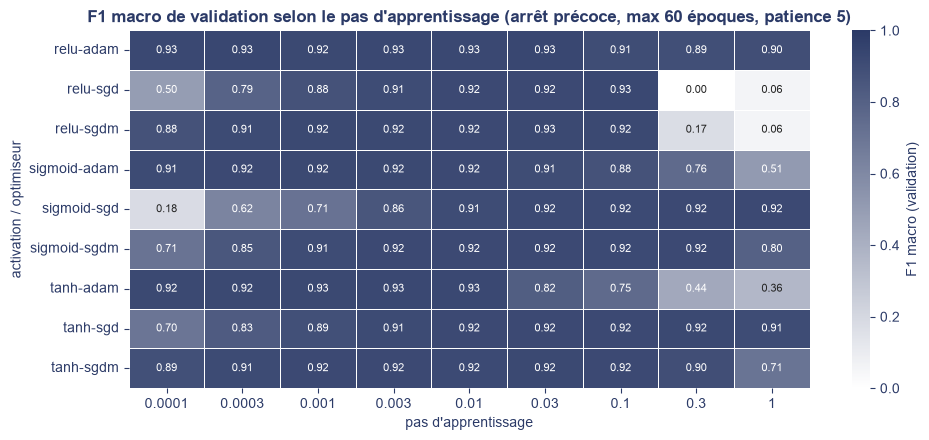

In [23]:
# Carte de chaleur : F1 macro de validation pour chaque (activation, optimiseur) et chaque pas
piv = grid.pivot_table(index=["act", "opt"], columns="lr", values="val_f1")
fig, ax = plt.subplots(figsize=(10, 4.5))
sns.heatmap(piv, annot=True, fmt=".2f", cmap=cmap_bleu, vmin=0, vmax=1, linewidths=0.5, linecolor=BLANC,
            annot_kws={"size": 8}, cbar_kws={"label": "F1 macro (validation)"}, ax=ax)
ax.set_xticklabels([f"{v:g}" for v in piv.columns], rotation=0)
ax.set_title(f"F1 macro de validation selon le pas d'apprentissage (arrêt précoce, max {GRID_EPOCHS} époques, patience {GRID_PATIENCE})")
ax.set_xlabel("pas d'apprentissage"); ax.set_ylabel("activation / optimiseur")
plt.tight_layout(); plt.show()

- La grille de pas d'apprentissage montre, pour chaque couple (activation, optimiseur), un large plateau où le F1 macro de validation atteint 0,92 à 0,93 (plages avec F1 ≥ 0,91 : Adam environ 10⁻⁴ à 10⁻² ; SGD et SGD avec momentum environ 10⁻² à 0,3, jusqu'à 1 pour sigmoid).
- Un pas trop petit conduit à un sous-apprentissage : avec SGD à 10⁻⁴, le F1 tombe à 0,18 (sigmoid), 0,50 (ReLU) et 0,70 (tanh), le réseau n'ayant pas convergé dans les 60 époques de la grille.
- Un pas trop grand conduit à une divergence : ReLU avec SGD à 0,3 donne un F1 de 0,00 (0,06 à 1) et ReLU avec momentum 0,17 (0,06 à 1) ; Adam se dégrade aussi avec de grands pas (tanh : 0,44 à 0,3).
- Le pas utile est plus petit pour Adam que pour SGD, et plus grand pour sigmoid que pour ReLU avec SGD (SGD avec momentum compris).

-> le choix de l'optimiseur et de l'activation change peu le F1 : le pas d'apprentissage compte beaucoup plus.

## Activations × optimiseurs (Question 2.2)

In [24]:
results = {}
for act in ACT_LIST:
    for o in OPTS:
        results[(act, o)] = run(act, o, best_lr[(act, o)], EPOCHS, patience=PATIENCE)

rows = []
for (act, o), r in results.items():
    h = r["hist"]; best = h.iloc[r["best_epoch"] - 1]
    rows.append({"activation": act, "optimiseur": o, "lr": best_lr[(act, o)],
                 "train F1": best["train_f1"], "val acc": best["val_acc"], "val F1": best["val_f1"],
                 "écart F1 (train - val)": best["train_f1"] - best["val_f1"],
                 "meilleure époque": r["best_epoch"], "époques faites": len(h),
                 "temps (s)": r["time"]})
tab = pd.DataFrame(rows)

display(tab.round(4))
display(tab.pivot(index="activation", columns="optimiseur", values="val F1").round(4))

,activation,optimiseur,lr,train F1,val acc,val F1,écart F1 (train - val),meilleure époque,époques faites,temps (s)
0,relu,sgd,0.100,0.9695,0.9103,0.9113,0.0582,5,15,2.3867
1,relu,sgdm,0.030,0.9613,0.9204,0.9212,0.0401,2,12,1.9877
2,relu,adam,0.030,0.9749,0.9221,0.9230,0.0519,3,13,2.4666
3,tanh,sgd,0.300,0.9767,0.9316,0.9317,0.0450,7,17,2.7044
4,tanh,sgdm,0.030,0.9745,0.9150,0.9158,0.0587,3,13,2.1435
5,tanh,adam,0.003,0.9906,0.9251,0.9264,0.0642,7,17,2.9817
6,sigmoid,sgd,1.000,0.9549,0.9080,0.9083,0.0465,4,14,2.3673
7,sigmoid,sgdm,0.300,0.9684,0.9103,0.9101,0.0583,4,14,2.2165
8,sigmoid,adam,0.003,0.9848,0.9204,0.9202,0.0647,7,17,2.9437


optimiseur,adam,sgd,sgdm
activation,,,
relu,0.9230,0.9113,0.9212
sigmoid,0.9202,0.9083,0.9101
tanh,0.9264,0.9317,0.9158


- Le MLP à une couche cachée fait à peine mieux que la régression logistique (F1 macro de validation 0,9187) : le meilleur résultat est tanh avec SGD (0,9317, soit +0,013), et quatre configurations sur neuf restent en dessous de la référence (de 0,9083 à 0,9158). Pas de vrai gain avec une seule couche cachée.

- Les F1 des 9 configurations sont compris entre 0,908 et 0,932 : avec une seule graine, ces écarts ne permettent pas de désigner une activation ou un optimiseur gagnant.

- SGD avec momentum atteint sa meilleure époque le plus tôt (2 à 4), Adam et SGD plus tard (3 à 7). 

- Accuracy et F1 macro sont presque identiques, puisque les classes sont équilibrées.

- Toutes les configurations surapprennent : le F1 d'entraînement vaut 0,955 à 0,991, soit un écart de 0,04 à 0,065 avec la validation. Le early stopping réduit cet écart (0,06 à 0,09 sans arrêt précoce, 40 époques), mais ne le supprime pas.

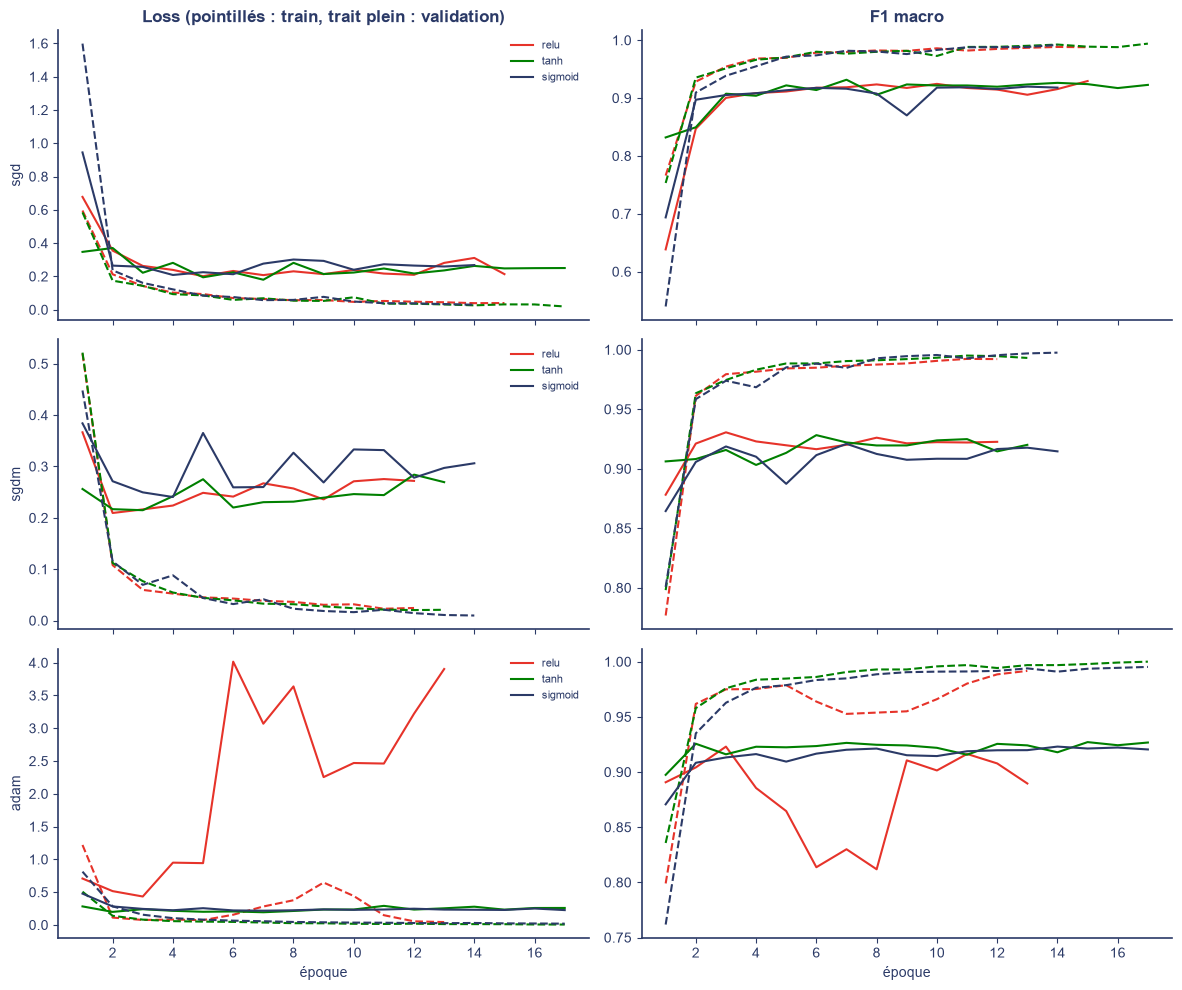

In [30]:
# Courbes d'apprentissage : une ligne par optimiseur, une couleur par activation
couleurs = {"sigmoid": BLEU, "relu": ROUGE, "tanh":  "#008000"}     # bleu, rouge, gris moyen

fig, axes = plt.subplots(3, 2, figsize=(12, 10), sharex=True)
for i, o in enumerate(OPTS):
    for act in ACT_LIST:
        h = results[(act, o)]["hist"]
        for j, m in enumerate(["loss", "f1"]):
            axes[i, j].plot(h["epoch"], h[f"train_{m}"], "--", color=couleurs[act])
            axes[i, j].plot(h["epoch"], h[f"val_{m}"], "-", color=couleurs[act], label=act)
    axes[i, 0].set_ylabel(o)
    axes[i, 0].legend(frameon=False, fontsize=8)
axes[0, 0].set_title("Loss (pointillés : train, trait plein : validation)")
axes[0, 1].set_title("F1 macro")
axes[2, 0].set_xlabel("époque"); axes[2, 1].set_xlabel("époque")
plt.tight_layout(); plt.show()

## Conclusions
- **Vitesse de convergence** : avec le early stopping, toutes les configurations atteignent leur minimum de loss de validation en 2 à 7 époques et passent de F1 ≈ 0,6 à plus de 0,90 en 2 à 3 époques. SGD avec momentum est le plus rapide (meilleure époque entre 2 et 4), Adam et SGD sont un peu plus lents (3 à 7).

- **Stabilité** : SGD donne des courbes de validation assez stables (loss autour de 0,2 à 0,3, quelques creux isolés de F1, par exemple sigmoid à l'époque 9). Avec momentum, sigmoid oscille davantage (loss entre 0,24 et 0,36). Le cas le plus instable est ReLU avec Adam au pas 0,03 : la loss de validation explose (jusqu'à 4) et le F1 chute à 0,81, alors que tanh et sigmoid avec Adam (pas 0,003) restent stables. Ce pas est trop grand pour Adam, la configuration n'est bonne que parce que l'arrêt précoce restaure l'époque 3.

- **Écart train / validation** : le F1 d'entraînement vaut 0,955 à 0,991 contre 0,908 à 0,932 en validation, soit un écart de 0,04 à 0,065 : les réseaux surapprennent. La loss de validation atteint son minimum tôt puis stagne ou remonte pendant que celle d'entraînement tend vers 0.

- **Effet de l'activation** : pas d'activation dominante. Tanh est la meilleure avec SGD (0,9317) et Adam (0,9264), ReLU est correcte avec Adam et momentum (0,923 et 0,921), sigmoid est la moins bonne avec SGD et momentum (0,908 et 0,910). Les écarts sont de l'ordre de 0,01 à 0,02.

- **Sensibilité au pas** : la carte de chaleur montre, pour chaque couple, un plateau où le F1 vaut 0,92 à 0,93. Un pas trop petit donne un sous-apprentissage, un pas trop grand une divergence. Le pas utile est plus petit pour Adam que pour SGD, et plus grand pour sigmoid que pour ReLU avec SGD.

- **Comparaison avec la référence** : la régression logistique atteint 0,9187. Le meilleur MLP (tanh/SGD, 0,9317) la dépasse de 0,013, et quatre configurations sur neuf restent en dessous : le MLP à une couche cachée n'apporte pas de gain net.



## Analyse par classe

In [27]:
best_key = tab.loc[tab["val F1"].idxmax(), ["activation", "optimiseur"]].tolist()
best_key = tuple(best_key)
best = results[best_key]
pred_best = evaluate(best["model"], val_loader)["pred"]
print("Meilleure combinaison (1 graine) :", best_key, "| pas =", best_lr[best_key])
print(classification_report(y_val, pred_best, target_names=classes, digits=3))

print("Répartition des classes en validation :")
print(pd.Series(y_val).map(dict(enumerate(classes))).value_counts(normalize=True).round(3).to_string())

Meilleure combinaison (1 graine) : ('tanh', 'sgd') | pas = 0.3
                    precision    recall  f1-score   support

            LAYING      0.991     1.000     0.996       336
           SITTING      0.871     0.919     0.894       309
          STANDING      0.927     0.869     0.897       320
           WALKING      0.882     0.948     0.914       269
WALKING_DOWNSTAIRS      0.939     0.955     0.947       224
  WALKING_UPSTAIRS      0.995     0.895     0.942       237

          accuracy                          0.932      1695
         macro avg      0.934     0.931     0.932      1695
      weighted avg      0.933     0.932     0.932      1695

Répartition des classes en validation :
LAYING                0.198
STANDING              0.189
SITTING               0.182
WALKING               0.159
WALKING_UPSTAIRS      0.140
WALKING_DOWNSTAIRS    0.132


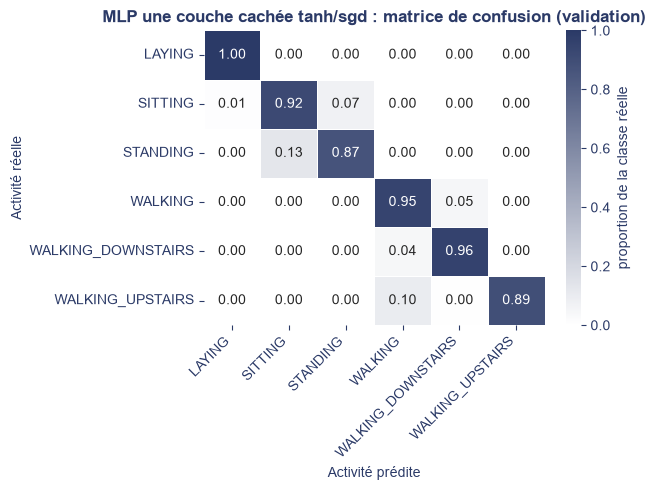

In [28]:
# Matrice de confusion du meilleur MLP (normalisée par ligne : proportion de chaque vraie classe)
cm = confusion_matrix(y_val, pred_best, labels=range(n_classes))
cmn = cm / cm.sum(axis=1, keepdims=True)
fig, ax = plt.subplots(figsize=(6.5, 5))
sns.heatmap(cmn, annot=True, fmt=".2f", cmap=cmap_bleu, vmin=0, vmax=1, xticklabels=classes, yticklabels=classes,
            linewidths=0.5, linecolor=BLANC, cbar_kws={"label": "proportion de la classe réelle"}, ax=ax)
ax.set_title(f"MLP une couche cachée {best_key[0]}/{best_key[1]} : matrice de confusion (validation)")
ax.set_xlabel("Activité prédite"); ax.set_ylabel("Activité réelle")
plt.setp(ax.get_xticklabels(), rotation=45, ha="right")
plt.tight_layout(); plt.show()

Sur la validation, l'accuracy (0,932) et le F1 macro (0,932) du meilleur MLP (tanh/SGD) sont identiques. C'est normal : les classes sont assez équilibrées, donc l'accuracy n'est pas dominée par une classe majoritaire, et le F1 macro, qui donne le même poids aux six activités, évolue de la même façon. Les deux mesures auraient divergé avec des classes très déséquilibrées.

Le F1 par classe est en revanche plus informatif : LAYING est quasi parfaite (0,996), les trois marches se situent entre 0,91 et 0,95, tandis que SITTING (0,894) et STANDING (0,897) sont les plus difficiles, avec 13 % des fenêtres "STANDING" classées " SITTING ". 

Le MLP améliore surtout les postures par rapport à la régression logistique (STANDING +0,037, SITTING +0,025), mais pas les marches (WALKING −0,009). 

# Variabilité des résultats

In [32]:
SEEDS = [0, 1, 2, 3, 4]

configs = [
    {"nom": "tanh / SGD",              "act": "tanh", "opt": "sgd",  "lr": best_lr[("tanh", "sgd")]},
    {"nom": "tanh / Adam",             "act": "tanh", "opt": "adam", "lr": best_lr[("tanh", "adam")]},
    {"nom": "relu / Adam (lr 0,03)",   "act": "relu", "opt": "adam", "lr": best_lr[("relu", "adam")]},
    {"nom": "relu / Adam (lr 0,001)",  "act": "relu", "opt": "adam", "lr": 1e-3},
]

seed_results = {}
for cfg in configs:
    runs = []
    for s in SEEDS:
        train_loader = make_loader(X_train_s, y_train, 128, shuffle=True, seed=s)
        r = run(cfg["act"], cfg["opt"], cfg["lr"], EPOCHS, seed=s, patience=PATIENCE)
        best = r["hist"].iloc[r["best_epoch"] - 1]
        runs.append({"graine": s, "val_f1": best["val_f1"], "val_acc": best["val_acc"],
                     "train_f1": best["train_f1"], "meilleure_epoque": r["best_epoch"]})
    seed_results[cfg["nom"]] = pd.DataFrame(runs)
    print(cfg["nom"], "terminé")

lignes = []
for cfg in configs:
    d = seed_results[cfg["nom"]]
    lignes.append({"configuration": cfg["nom"], "lr": cfg["lr"],
                   "val F1 (moy ± std)": f"{d['val_f1'].mean():.4f} ± {d['val_f1'].std():.4f}",
                   "val acc (moy ± std)": f"{d['val_acc'].mean():.4f} ± {d['val_acc'].std():.4f}",
                   "écart F1 train - val": round((d["train_f1"] - d["val_f1"]).mean(), 4),
                   "meilleure époque (moy)": round(d["meilleure_epoque"].mean(), 1)})
tab_seeds = pd.DataFrame(lignes)
display(tab_seeds)


tanh / SGD terminé
tanh / Adam terminé
relu / Adam (lr 0,03) terminé
relu / Adam (lr 0,001) terminé


,configuration,lr,val F1 (moy ± std),val acc (moy ± std),écart F1 train - val,meilleure époque (moy)
0,tanh / SGD,0.300,0.9219 ± 0.0056,0.9215 ± 0.0056,0.0515,7.0
1,tanh / Adam,0.003,0.9209 ± 0.0033,0.9199 ± 0.0031,0.0636,6.0
2,"relu / Adam (lr 0,03)",0.030,0.9126 ± 0.0085,0.9114 ± 0.0087,0.0243,3.0
3,"relu / Adam (lr 0,001)",0.001,0.9282 ± 0.0037,0.9274 ± 0.0035,0.0560,8.2


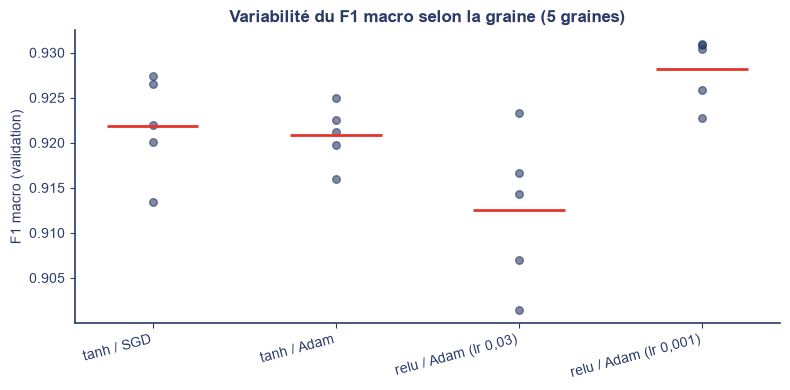

In [35]:
fig, ax = plt.subplots(figsize=(8, 4))
for i, cfg in enumerate(configs):
    d = seed_results[cfg["nom"]]["val_f1"]
    ax.scatter([i] * len(d), d, color=BLEU, alpha=0.6, s=30)           # un point par graine
    ax.hlines(d.mean(), i - 0.25, i + 0.25, color=ROUGE, linewidth=2)  # moyenne
ax.set_xticks(range(len(configs))); ax.set_xticklabels([c["nom"] for c in configs], rotation=15, ha="right")
ax.set_ylabel("F1 macro (validation)"); ax.set_title(f"Variabilité du F1 macro selon la graine ({len(SEEDS)} graines)")
plt.tight_layout(); plt.show()

**Bilan de la variabilité ** 
 Le classement à une graine était trompeur : le meilleur score isolé (tanh/SGD, 0,9317) est au-dessus de tous ses scores sur 5 graines. Le pas 0,03 retenu par la grille est instable, alors que 0,001 améliore le F1 de 0,016 et divise l'écart-type par deux. tanh/SGD et tanh/Adam ne se distinguent pas.

-> ReLU avec Adam et un pas de 0,001 (F1 = 0,9282 ± 0,0037). C’est la plus haute moyenne sur 5 graines, la plus stable des quatre, et la seule à dépasser la régression logistique (0,9187) de plus d’un écart-type.